In [21]:
!pip -q install pypdf transformers accelerate sentence-transformers faiss-cpu "pandas==2.2.3" "bottleneck>=1.5" matplotlib

from google.colab import files
from pathlib import Path
import json, re, hashlib
import torch
from pypdf import PdfReader
from transformers import AutoTokenizer

output_dir = Path("/content/eswatini_outputs")
output_dir.mkdir(exist_ok=True)

uploaded = files.upload()
pdf_files = [name for name in uploaded if name.lower().endswith(".pdf")]

if len(pdf_files) != 1:
    raise ValueError("Upload exactly one IMF PDF.")

pdf_path = Path(pdf_files[0])
tokenizer = AutoTokenizer.from_pretrained(
    "ibm-granite/granite-3.3-8b-instruct"
)

print("PDF:", pdf_path.name)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Output folder:", output_dir)

Saving 1934-7685-002.2026.issue-260-en.pdf to 1934-7685-002.2026.issue-260-en (1).pdf
PDF: 1934-7685-002.2026.issue-260-en (1).pdf
GPU: NVIDIA A100-SXM4-80GB
Output folder: /content/eswatini_outputs


In [22]:
reader = PdfReader(str(pdf_path))

def clean_text(text):
    text = text.replace("\x00", " ")
    text = re.sub(r"(?m)^\s*©?\s*International Monetary Fund\. Not for Redistribution\s*$", "", text, flags=re.I)
    text = re.sub(r"(?m)^\s*INTERNATIONAL MONETARY FUND\s+\d+\s*$", "", text)
    text = re.sub(r"(?m)^\s*\d+\s+INTERNATIONAL MONETARY FUND\s*$", "", text)
    text = re.sub(r"(?m)^\s*KINGDOM OF ESWATINI\s*$", "", text)
    text = re.sub(r"([A-Za-z])-\s*\n\s*([a-z])", r"\1\2", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

pages = []

for page_no, page in enumerate(reader.pages, start=1):
    raw_text = page.extract_text() or ""
    cleaned = clean_text(raw_text)
    pages.append({
        "page": page_no,
        "text": cleaned,
        "characters": len(cleaned)
    })

full_text = "\n\n".join(
    p["text"] for p in pages if p["text"]
)

(output_dir / "eswatini_cleaned_text.txt").write_text(
    full_text, encoding="utf-8"
)

with open(output_dir / "eswatini_pages.json", "w") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Total PDF pages:", len(reader.pages))
print("Pages with text:", sum(bool(p["text"]) for p in pages))
print("Total cleaned characters:", len(full_text))

Total PDF pages: 85
Pages with text: 84
Total cleaned characters: 197396


In [23]:
chunk_size = 400
overlap = 50
chunks = []

for page in pages:
    if not page["text"]:
        continue

    token_ids = tokenizer.encode(
        page["text"], add_special_tokens=False
    )

    start = 0
    while start < len(token_ids):
        end = min(start + chunk_size, len(token_ids))
        chunk_text = tokenizer.decode(
            token_ids[start:end], skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": chunk_text,
            "token_count": end - start
        })

        if end == len(token_ids):
            break

        start = end - overlap

with open(output_dir / "eswatini_chunks.json", "w") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Total chunks:", len(chunks))
print("Average tokens:", round(
    sum(c["token_count"] for c in chunks) / len(chunks), 1
))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("Chunk size:", chunk_size)
print("Token overlap:", overlap)

Total chunks: 208
Average tokens: 325.8
Pages covered: 84
Chunk size: 400
Token overlap: 50


In [24]:
from transformers import AutoModelForCausalLM
import torch

model_name = "ibm-granite/granite-3.3-8b-instruct"

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)
model.eval()

def ask_granite(prompt, max_new_tokens=180):
    messages = [
        {
            "role": "system",
            "content": "You are a financial analyst. Use only the provided IMF text. Do not invent facts or numerical values."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    # Handle BatchEncoding and tensor outputs
    if hasattr(inputs, "input_ids"):
        inputs = inputs["input_ids"]

    inputs = inputs.to(next(model.parameters()).device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    return response.strip()

Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

In [25]:
section_names = [
    "BACKGROUND AND CONTEXT",
    "RECENT DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "A. ANCHORING DEBT AND FISCAL SUSTAINABILITY",
    "B. SAFEGUARDING THE PEG",
    "C. CONTINUING FINANCIAL SECTOR REFORMS",
    "D. SUPPORTING PRIVATE-SECTOR-LED GROWTH AND JOB CREATION",
    "CAPACITY DEVELOPMENT AND DATA ISSUES",
    "STAFF APPRAISAL"
]

# Exclude cover, press release and table of contents.
staff_text = "\n\n".join(
    p["text"] for p in pages if p["page"] >= 11
)

heading_pattern = re.compile(
    r"(?im)^\s*(" +
    "|".join(re.escape(s) for s in section_names) +
    r")\s*$"
)

matches = list(heading_pattern.finditer(staff_text))
positions = {}

for match in matches:
    heading = match.group(1).upper()
    if heading not in positions:
        positions[heading] = (match.start(), match.end())

missing = [s for s in section_names if s not in positions]

if missing:
    raise ValueError(f"Section headings not found: {missing}")

if any(
    positions[section_names[i]][0] >= positions[section_names[i+1]][0]
    for i in range(len(section_names)-1)
):
    raise ValueError("Section headings are not in expected order.")

sections = {}

for i, name in enumerate(section_names):
    start = positions[name][1]
    end = (
        positions[section_names[i+1]][0]
        if i+1 < len(section_names)
        else len(staff_text)
    )

    sections[name] = staff_text[start:end].strip()

print("Sections identified:", len(sections))

for name, content in sections.items():
    print(name, "-", len(content), "characters")

# Keep Staff Appraisal separate from figures, tables and annexes
staff_pages = [
    p["text"] for p in pages
    if 31 <= p["page"] <= 33
]

appraisal_text = "\n\n".join(staff_pages)

match = re.search(
    r"(?im)^\s*STAFF APPRAISAL\s*$",
    appraisal_text
)

if not match:
    raise ValueError("Staff Appraisal heading not found.")

sections["STAFF APPRAISAL"] = appraisal_text[match.end():].strip()

# Save the corrected nine report sections
with open(output_dir / "eswatini_sections.json", "w") as f:
    json.dump(sections, f, indent=2, ensure_ascii=False)

print("FINAL SECTION EXTRACTION")
print("Sections identified:", len(sections))

for name, content in sections.items():
    print(f"{name}: {len(content):,} characters")

Sections identified: 9
BACKGROUND AND CONTEXT - 5434 characters
RECENT DEVELOPMENTS - 7492 characters
OUTLOOK AND RISKS - 8959 characters
A. ANCHORING DEBT AND FISCAL SUSTAINABILITY - 25265 characters
B. SAFEGUARDING THE PEG - 3454 characters
C. CONTINUING FINANCIAL SECTOR REFORMS - 3134 characters
D. SUPPORTING PRIVATE-SECTOR-LED GROWTH AND JOB CREATION - 5715 characters
CAPACITY DEVELOPMENT AND DATA ISSUES - 2445 characters
STAFF APPRAISAL - 113485 characters
FINAL SECTION EXTRACTION
Sections identified: 9
BACKGROUND AND CONTEXT: 5,434 characters
RECENT DEVELOPMENTS: 7,492 characters
OUTLOOK AND RISKS: 8,959 characters
A. ANCHORING DEBT AND FISCAL SUSTAINABILITY: 25,265 characters
B. SAFEGUARDING THE PEG: 3,454 characters
C. CONTINUING FINANCIAL SECTOR REFORMS: 3,134 characters
D. SUPPORTING PRIVATE-SECTOR-LED GROWTH AND JOB CREATION: 5,715 characters
CAPACITY DEVELOPMENT AND DATA ISSUES: 2,445 characters
STAFF APPRAISAL: 6,492 characters


In [26]:
import json
from pathlib import Path

summary_file = output_dir / "eswatini_section_summaries.json"
executive_file = output_dir / "eswatini_executive_summary.json"

if summary_file.exists():
    section_summaries = json.loads(summary_file.read_text())
else:
    section_summaries = {}

def split_for_summary(text, max_tokens=1800):
    ids = tokenizer.encode(text, add_special_tokens=False)
    return [
        tokenizer.decode(ids[i:i+max_tokens],
                         skip_special_tokens=True,
                         clean_up_tokenization_spaces=False)
        for i in range(0, len(ids), max_tokens)
    ]

for name, content in sections.items():
    if name in section_summaries:
        continue

    parts = split_for_summary(content)
    notes = []

    for part in parts:
        prompt = f"""
Summarise this section from the IMF Eswatini 2026 report.

Section: {name}

Extract the main economic developments, financial figures,
policy recommendations and risks that appear in the text.
Use only the supplied source.
Write a concise factual paragraph of about 70 words.
Do not invent figures or include outside information.

SOURCE:
{part}
"""
        notes.append(ask_granite(prompt, max_new_tokens=140))

    combined_notes = "\n\n".join(notes)

    final_prompt = f"""
Write a final summary of this IMF report section.

Section: {name}

Requirements:
- Strictly fewer than 100 words.
- Use clear, professional English.
- Preserve important financial figures and policy implications.
- Avoid repetition and unsupported claims.
- Output only the summary paragraph.

SOURCE NOTES:
{combined_notes}
"""

    summary = ask_granite(final_prompt, max_new_tokens=160)

    if len(summary.split()) >= 100:
        summary = ask_granite(
            final_prompt + "\nRewrite in no more than 80 words.",
            max_new_tokens=130
        )

    if len(summary.split()) >= 100:
        raise ValueError(f"Summary exceeds word limit: {name}")

    section_summaries[name] = summary

    summary_file.write_text(
        json.dumps(section_summaries, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

print("Section summaries saved:", len(section_summaries))
print({name:len(value.split()) for name,value in section_summaries.items()})

Section summaries saved: 9
{'BACKGROUND AND CONTEXT': 69, 'RECENT DEVELOPMENTS': 75, 'OUTLOOK AND RISKS': 81, 'A. ANCHORING DEBT AND FISCAL SUSTAINABILITY': 79, 'B. SAFEGUARDING THE PEG': 77, 'C. CONTINUING FINANCIAL SECTOR REFORMS': 61, 'D. SUPPORTING PRIVATE-SECTOR-LED GROWTH AND JOB CREATION': 74, 'CAPACITY DEVELOPMENT AND DATA ISSUES': 82, 'STAFF APPRAISAL': 72}


In [27]:
# Regenerate only the executive summary using verified PDF context

source_pages = [2, 3, 6, 7, 15, 16]

evidence = "\n\n".join(
    f"PDF PAGE {p['page']}:\n{p['text']}"
    for p in pages if p["page"] in source_pages
)

summary_context = "\n\n".join(
    f"{name}: {summary}"
    for name, summary in section_summaries.items()
)

prompt = f"""
Prepare an accurate executive summary of the IMF Eswatini
2026 Article IV Consultation.

Write exactly 6 concise bullet points covering:
1. Economic growth and outlook
2. Inflation and monetary policy
3. Fiscal balance and public debt
4. Banking sector and financial stability
5. Structural reforms and employment
6. Major economic risks and policy implications

Rules:
- Use only the IMF evidence below.
- Distinguish historical values from forecasts.
- Preserve the correct year, units and fiscal period.
- Do not confuse total regulatory capital with Tier 1 capital.
- Do not invent missing numerical indicators.
- Avoid unsupported claims and calculations.
- Write no more than 250 words in total.
- Output only the six bullet points.

IMF SOURCE EVIDENCE:
{evidence}

SECTION SUMMARIES:
{summary_context}
"""

executive_summary = ask_granite(
    prompt,
    max_new_tokens=750
)

bullet_lines = [
    line.strip() for line in executive_summary.splitlines()
    if re.match(r"^(?:[-*•]|\d+[.)])\s", line.strip())
]

if len(bullet_lines) != 6:
    print("Warning: Expected 6 numbered or bulleted points; review the output.")

executive_file.write_text(
    json.dumps(executive_summary, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("EXECUTIVE SUMMARY\n")
print(executive_summary)
print("\nBullet points:", len(bullet_lines))
print("Total words:", len(executive_summary.split()))

EXECUTIVE SUMMARY

1. Economic growth strengthened to 4.9% in 2025, driven by large public and private investment, and is projected to moderate to 3.7% in 2026, reflecting high fuel prices and fiscal consolidation.
2. Public debt rose sharply in FY25/26, driven by higher public investment, wages, and other current spending, reaching 44.8% of GDP. Consolidation is planned over the medium term to place public debt on a downward path, peaking at 54.4% in FY27/28.
3. Inflation fell to 3.1% in 2025 and remained moderate at 2.5% through July 2026, partly supported by the Fuel Price Regulation Mechanism, which raised fuel prices by 39% by September 2026.
4. The banking sector remains well-capitalized and liquid, though asset quality is uneven. The regulatory capital-to-risk-weighted assets ratio decreased to 18.6% in March 2026, and the NPL ratio was 7.3%. Credit to the private sector grew by 10.1% year-on-year in June 2026.
5. The current account surplus widened from 2.1% of GDP in 2024 to 2

In [28]:
import json
import re

financial_file = output_dir / "eswatini_financial_data.json"

fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

# Relevant PDF pages, selected by financial terminology
terms = [
    "selected economic indicators",
    "policy rate",
    "nonperforming loans",
    "non-performing loans",
    "tier 1",
    "unemployment",
    "financial soundness indicators"
]

relevant_pages = [
    p for p in pages
    if any(term in p["text"].lower() for term in terms)
]

# Prioritise key pages and preserve original source references
priority_pages = [6, 11, 15]

selected = {
    p["page"]: p for p in pages
    if p["page"] in priority_pages
}

for p in relevant_pages:
    if len(selected) >= 12:
        break
    selected[p["page"]] = p

evidence = "\n\n".join(
    f"PDF PAGE {p['page']}:\n{p['text'][:6500]}"
    for p in selected.values()
)

prompt = f"""
Extract financial indicators from the IMF Eswatini 2026 report.

Return ONLY a valid JSON object containing exactly:
{json.dumps(fields)}

Requirements:
- Country name must be "Eswatini".
- GDP growth forecast: use the 2026 projection.
- Inflation: use the 2026 annual average CPI projection.
- Central bank policy rate: use the rate stated in the report.
- NPL ratio: use the latest clearly reported value.
- Unemployment: use the latest reported overall rate.
- Tier 1 capital: use Tier 1 capital specifically, not
  total regulatory capital.
- All numerical values must be percentages, not decimals.
- Use null for missing or unverifiable indicators.
- Do not invent values.
- Do not include explanations or Markdown.

IMF SOURCE:
{evidence}
"""

raw = ask_granite(prompt, max_new_tokens=350)

try:
    match = re.search(r"\{.*?\}", raw, re.DOTALL)
    if not match:
        raise ValueError("No JSON object returned")

    extracted = json.loads(match.group())

    financial_data = {"country_name": "Eswatini"}

    for field in fields[1:]:
        value = extracted.get(field)
        try:
            financial_data[field] = (
                float(value) if value is not None else None
            )
        except (ValueError, TypeError):
            financial_data[field] = None

except (ValueError, json.JSONDecodeError):
    financial_data = {
        "country_name": "Eswatini",
        **{field: None for field in fields[1:]}
    }

financial_file.write_text(
    json.dumps(financial_data, indent=2),
    encoding="utf-8"
)

print("ESWATINI FINANCIAL JSON\n")
print(json.dumps(financial_data, indent=2))

ESWATINI FINANCIAL JSON

{
  "country_name": "Eswatini",
  "gdp_growth_forecast_pct": 3.7,
  "headline_inflation_rate_pct": 2.9,
  "central_bank_policy_rate_pct": 6.75,
  "non_performing_loan_ratio": 7.3,
  "unemployment_rate_pct": 33.5,
  "tier_1_capital_ratio": null
}


In [29]:
# Preserve the model's original output and record the documented human correction.
audit_file = output_dir / "eswatini_financial_human_audit.json"
original_file = output_dir / "eswatini_financial_original.json"
if not original_file.exists():
    original_file.write_text(json.dumps(financial_data, indent=2), encoding="utf-8")
financial_data["tier_1_capital_ratio"] = 16.3
financial_file.write_text(json.dumps(financial_data, indent=2), encoding="utf-8")
audit_file.write_text(json.dumps({
    "indicator": "tier_1_capital_ratio",
    "initial_value": None,
    "verified_value": 16.3,
    "source": "IMF Country Report 26/260, PDF page 43, Table 5, 2026 Q1",
    "method": "Human source-table correction; not independently extracted by Granite"
}, indent=2), encoding="utf-8")
print("FINAL FINANCIAL JSON:", json.dumps(financial_data, indent=2))

FINAL FINANCIAL JSON: {
  "country_name": "Eswatini",
  "gdp_growth_forecast_pct": 3.7,
  "headline_inflation_rate_pct": 2.9,
  "central_bank_policy_rate_pct": 6.75,
  "non_performing_loan_ratio": 7.3,
  "unemployment_rate_pct": 33.5,
  "tier_1_capital_ratio": 16.3
}


In [30]:
import re
import json
import pandas as pd

themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bCPI\b", r"\bprice pressures?\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rates?\b",
        r"\bcredit\b", r"\blending\b", r"\bborrowing costs?\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bproperty\b", r"\bmortgages?\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank(?:ing|s)?\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\bcapital ratios?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bsovereign debt\b",
        r"\bdebt sustainability\b", r"\bfiscal deficits?\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabor market\b", r"\blabour market\b",
        r"\bwages?\b", r"\bjob creation\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risk\b",
        r"\bfinancial risks?\b", r"\bfinancial vulnerabilities\b",
        r"\bmacroprudential\b"
    ]
}

theme_results = []

for theme, patterns in themes.items():
    combined_pattern = "|".join(patterns)
    count = len(re.findall(
        combined_pattern, full_text, flags=re.IGNORECASE
    ))

    theme_results.append({
        "theme": theme,
        "count": count
    })

theme_df = pd.DataFrame(theme_results)

total_matches = theme_df["count"].sum()

theme_df["percentage"] = (
    theme_df["count"] / total_matches * 100
).round(2) if total_matches else 0.0

theme_df = theme_df.sort_values(
    "count", ascending=False
).reset_index(drop=True)

theme_df.to_csv(
    output_dir / "eswatini_financial_themes.csv",
    index=False
)

(output_dir / "eswatini_financial_themes.json").write_text(
    theme_df.to_json(orient="records", indent=2),
    encoding="utf-8"
)

print("ESWATINI FINANCIAL THEME DISTRIBUTION\n")
print(theme_df.to_string(index=False))
print("\nTotal theme matches:", total_matches)
print("Total themes:", len(theme_df))

ESWATINI FINANCIAL THEME DISTRIBUTION

                      theme  count  percentage
Banking Capital & Liquidity    102       25.37
             Sovereign Debt     77       19.15
    Interest Rates & Credit     70       17.41
      Labor Market Dynamics     65       16.17
         Inflation & Prices     56       13.93
    Systemic Financial Risk     23        5.72
      Housing & Real Estate      9        2.24

Total theme matches: 402
Total themes: 7


In [31]:
import json
import re

insights_file = output_dir / "eswatini_qualitative_insights.json"

if insights_file.exists():
    insights = json.loads(insights_file.read_text(encoding="utf-8"))
else:
    # Use the report's main economic and policy sections
    selected_sections = [
        "BACKGROUND AND CONTEXT",
        "RECENT DEVELOPMENTS",
        "OUTLOOK AND RISKS",
        "C. CONTINUING FINANCIAL SECTOR REFORMS",
        "D. SUPPORTING PRIVATE-SECTOR-LED GROWTH AND JOB CREATION",
        "STAFF APPRAISAL"
    ]

    source = "\n\n".join(
        f"{name}:\n{sections[name][:5500]}"
        for name in selected_sections
    )

    prompt = f"""
Analyse the IMF Eswatini 2026 report.

Extract exactly:
- 6 national economic strengths or growth drivers
- 6 economic vulnerabilities or financial risks

Return ONLY valid JSON using this structure:
{{
  "strengths": ["item 1", "item 2"],
  "vulnerabilities": ["item 1", "item 2"]
}}

Rules:
- Each list must contain exactly 6 distinct items.
- Each item should be one concise factual sentence.
- Base every finding on the supplied IMF text.
- Focus on macroeconomic and financial significance.
- Do not invent information or numerical values.
- Do not include Markdown or explanations.

IMF SOURCE:
{source}
"""

    raw = ask_granite(prompt, max_new_tokens=950)

    match = re.search(r"\{.*\}", raw, re.DOTALL)
    if not match:
        raise ValueError("Granite did not return a JSON object.")

    insights = json.loads(match.group())

    for key in ["strengths", "vulnerabilities"]:
        items = insights.get(key)
        if not isinstance(items, list) or len(items) != 6:
            raise ValueError(f"Expected 6 items for {key}.")
        if not all(isinstance(x, str) and x.strip() for x in items):
            raise ValueError(f"Invalid qualitative items: {key}")

    insights_file.write_text(
        json.dumps(insights, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

print("ESWATINI ECONOMIC STRENGTHS")
for i, item in enumerate(insights["strengths"], 1):
    print(f"{i}. {item}")

print("\nESWATINI ECONOMIC VULNERABILITIES")
for i, item in enumerate(insights["vulnerabilities"], 1):
    print(f"{i}. {item}")

ESWATINI ECONOMIC STRENGTHS
1. Eswatini's economy is highly open, with trade in goods and services exceeding GDP.
2. Exports are dominated by food and related chemical products, which are significant for both exports and imports.
3. The large public sector accounts for about one-third of the formal labor force and pays a wage premium.
4. The authorities have identified infrastructure, manufacturing, mining, tourism, and agriculture as key growth drivers.
5. Growth accelerated in 2025 to 4.9 percent, led by wholesale and retail trade, services, finance, and manufacturing.
6. The external position in 2025 was moderately stronger than implied by macroeconomic fundamentals and desirable policies.

ESWATINI ECONOMIC VULNERABILITIES
1. Persistent structural constraints, notably infrastructure gaps, labor market mismatches, and weaknesses in public administration, have held back growth.
2. Unemployment remains elevated at 33.5 percent overall and 52.2 percent among youth in 2025.
3. Ambitious

In [32]:
import re
import json
import pandas as pd

# IMF Selected Economic Indicators table, PDF page 6
table_text = pages[5]["text"]

indicators = {
    "Real GDP Growth": "Real GDP growth",
    "Average CPI Inflation": "CPI Inflation, average",
    "Public Debt": "Public debt, gross",
    "Current Account Balance": "Current account balance"
}

years = list(range(2023, 2032))
trend_data = {"Year": years}

for name, label in indicators.items():
    matching_lines = [
        line.strip() for line in table_text.splitlines()
        if line.strip().lower().startswith(label.lower())
    ]

    if len(matching_lines) != 1:
        raise ValueError(f"Cannot uniquely identify: {name}")

    line = matching_lines[0]
    values_text = line[len(label):]
    values_text = re.sub(r"^\s*\d+/", "", values_text)

    values = [
        float(v.replace(",", ""))
        for v in re.findall(
            r"(?<![\w.])-?\d+(?:,\d{3})*(?:\.\d+)?(?![\w.])",
            values_text
        )
    ]

    if len(values) != len(years):
        raise ValueError(
            f"{name}: expected 9 values, found {len(values)}"
        )

    trend_data[name] = values

trend_df = pd.DataFrame(trend_data)

# Distinguish historical estimates from projections
trend_df["Period"] = trend_df["Year"].apply(
    lambda year: "Historical/Estimate" if year <= 2025
    else "Projection"
)

trend_df.to_csv(
    output_dir / "eswatini_economic_trends.csv",
    index=False
)

(output_dir / "eswatini_economic_trends.json").write_text(
    trend_df.to_json(orient="records", indent=2),
    encoding="utf-8"
)

print("ESWATINI ECONOMIC TRENDS: 2023–2031\n")
print(trend_df.to_string(index=False))

print("\nTrend series:", len(indicators))
print("Years covered:", len(trend_df))

ESWATINI ECONOMIC TRENDS: 2023–2031

 Year  Real GDP Growth  Average CPI Inflation  Public Debt  Current Account Balance              Period
 2023              3.5                    4.9         39.4                      2.2 Historical/Estimate
 2024              3.0                    4.0         40.0                      2.1 Historical/Estimate
 2025              4.9                    3.1         44.8                      2.4 Historical/Estimate
 2026              3.7                    2.9         52.4                      1.8          Projection
 2027              3.4                    3.2         54.4                      1.9          Projection
 2028              3.4                    3.0         54.3                      2.0          Projection
 2029              3.3                    3.0         53.8                      2.4          Projection
 2030              3.3                    3.0         51.3                      2.6          Projection
 2031              3.3     

In [33]:
import faiss
import hashlib
import numpy as np
from sentence_transformers import SentenceTransformer

index_file = output_dir / "eswatini_faiss.index"
metadata_file = output_dir / "eswatini_rag_metadata.json"

embedding_model_name = "BAAI/bge-small-en-v1.5"
embedding_model = SentenceTransformer(
    embedding_model_name,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

chunk_texts = [c["text"] for c in chunks]

source_hash = hashlib.sha256(
    json.dumps(chunks, sort_keys=True).encode("utf-8")
).hexdigest()

rebuild = True

if index_file.exists() and metadata_file.exists():
    metadata = json.loads(metadata_file.read_text())
    if (metadata.get("source_hash") == source_hash
        and metadata.get("model") == embedding_model_name):
        index = faiss.read_index(str(index_file))
        rebuild = index.ntotal != len(chunks)

if rebuild:
    embeddings = embedding_model.encode(
        chunk_texts,
        batch_size=32,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_file))
    metadata_file.write_text(json.dumps({
        "model": embedding_model_name,
        "source_hash": source_hash,
        "chunk_count": len(chunks),
        "embedding_dimension": index.d
    }, indent=2))

print("Embedding model:", embedding_model_name)
print("Indexed chunks:", index.ntotal)
print("Embedding dimensions:", index.d)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding model: BAAI/bge-small-en-v1.5
Indexed chunks: 208
Embedding dimensions: 384


In [34]:
rag_file = output_dir / "eswatini_rag_audit.json"

def retrieve_context(question, top_k=5):
    query = embedding_model.encode(
        ["Represent this sentence for searching relevant passages: " + question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(query, top_k)

    return [
        {
            "page": chunks[int(i)]["page"],
            "chunk_id": chunks[int(i)]["chunk_id"],
            "score": round(float(score), 4),
            "text": chunks[int(i)]["text"]
        }
        for i, score in zip(indices[0], scores[0])
        if i >= 0
    ]

questions = [
    "What are the IMF's main recommendations for reducing Eswatini's public debt?",
    "Why should Eswatini align its monetary policy rate with South Africa?",
    "What are the main banking sector vulnerabilities and financial stability recommendations?",
    "What economic risks could affect Eswatini's growth outlook in 2026?"
]

rag_results = []

for question in questions:
    retrieved = retrieve_context(question)

    context = "\n\n".join(
        f"[PDF page {r['page']}, chunk {r['chunk_id']}]\n{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using only the retrieved IMF evidence.

Rules:
- Provide a concise factual answer of 80-120 words.
- Do not invent financial information.
- Cite the PDF page numbers supporting your claims.
- If evidence is insufficient, explicitly say so.
- Do not use knowledge outside the retrieved passages.

QUESTION:
{question}

RETRIEVED IMF EVIDENCE:
{context}
"""

    answer = ask_granite(prompt, max_new_tokens=250)

    rag_results.append({
        "question": question,
        "answer": answer,
        "retrieved_context": retrieved
    })

original_rag_file = output_dir / "eswatini_rag_initial.json"
original_rag_file.write_text(json.dumps(rag_results, indent=2, ensure_ascii=False), encoding="utf-8")
rag_file.write_text(json.dumps(rag_results, indent=2, ensure_ascii=False), encoding="utf-8")

print("ESWATINI RAG RESULTS\n")

for i, result in enumerate(rag_results, 1):
    print(f"QUESTION {i}: {result['question']}")
    print("Retrieved pages:",
          [r["page"] for r in result["retrieved_context"]])
    print("Answer:", result["answer"])

ESWATINI RAG RESULTS

QUESTION 1: What are the IMF's main recommendations for reducing Eswatini's public debt?
Retrieved pages: [24, 64, 62, 12, 32]
Answer: The IMF recommends that Eswatini target public debt at the midpoint of the estimated range, which is 40 percent of GDP, given the uncertain global environment and less favorable debt dynamics (PDF page 64, chunk 167). The IMF also suggests that Eswatini should reduce its high borrowing costs and improve its debt carrying capacity, particularly compared to South Africa and more financially developed small states (PDF page 64, chunk 167). Additionally, the IMF emphasizes the importance of identifying an appropriate debt anchor to balance competing policy objectives and provide a transparent guide for sustainable debt levels (PDF page 62, chunk 161). The IMF also recommends prudent debt management, greater use of lower-cost IFI financing, and careful management of the debt maturity profile to avoid lumpy amortization (PDF page 32, chu

In [35]:
for result in rag_results:
    context = "\n\n".join(
        f"PDF page {r['page']}:\n{r['text']}"
        for r in result["retrieved_context"][:3]
    )

    prompt = f"""
Answer the question using ONLY the IMF 2026 evidence.

Write 45-65 words in 2-3 complete sentences.

Rules:
- Answer directly and accurately.
- Mention only the most important facts.
- Use the citation format (PDF page X).
- Do not mention IMF 2025 or other publications.
- Avoid repetition.
- Finish with a complete sentence.
- Output only the answer.

Question: {result['question']}

Evidence:
{context}
"""

    answer = ask_granite(prompt, max_new_tokens=260)

    # One retry if the answer is incomplete
    if not answer.rstrip().endswith((".", "!", "?")) or len(answer.split()) > 90:
        answer = ask_granite(
            prompt + "\nKeep the answer under 50 words.",
            max_new_tokens=260
        )

    result["answer"] = answer

rag_file.write_text(
    json.dumps(rag_results, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("FINAL RAG ANSWERS\n")

for i, result in enumerate(rag_results, 1):
    answer = result["answer"]
    complete = answer.rstrip().endswith((".", "!", "?"))
    print(f"Question {i}: {len(answer.split())} words")
    print("Ending:", "Complete" if complete else "Needs review")
    print(answer)

FINAL RAG ANSWERS

Question 1: 62 words
Ending: Complete
The IMF recommends Eswatini target public debt at 40% of GDP, given uncertain global conditions and rising borrowing costs (PDF p. 64). To address high debt service burdens, the IMF suggests reducing interest payments and improving debt carrying capacity (PDF p. 62, 64). Establishing a debt anchor, absent in Eswatini, could help balance policy objectives and preserve fiscal space (PDF p. 64).
Question 2: 60 words
Ending: Complete
Eswatini should align its monetary policy rate with South Africa to anchor inflation, lower interest rates, and enhance policy signal credibility (IMF 2026, PDF page 27). The current divergence between the CBE's discount rate and the SARB's repo rate obscures policy signals (IMF 2025). Eswatini's peg to the South African rand also necessitates such alignment (IMF 2026, PDF page 79).
Question 3: 84 words
Ending: Complete
The main banking sector vulnerabilities include variations in asset quality, with dep

In [36]:
import gc
import torch
import json
import re
from transformers import AutoTokenizer, AutoModelForCausalLM

# Free Granite GPU memory before loading the evaluator
if "model" in globals():
    del model
if "tokenizer" in globals():
    del tokenizer

gc.collect()
torch.cuda.empty_cache()

judge_name = "mistralai/Mistral-7B-Instruct-v0.3"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)
judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)
judge_model.eval()

def ask_mistral(prompt, max_new_tokens=220):
    messages = [
        {"role": "user", "content": prompt}
    ]

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    if hasattr(inputs, "input_ids"):
        inputs = inputs["input_ids"]

    inputs = inputs.to(next(judge_model.parameters()).device)

    with torch.inference_mode():
        output = judge_model.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    return judge_tokenizer.decode(
        output[0][inputs.shape[-1]:],
        skip_special_tokens=True
    ).strip()

print("Mistral evaluator loaded successfully!")
print("Evaluator:", judge_name)
print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Mistral evaluator loaded successfully!
Evaluator: mistralai/Mistral-7B-Instruct-v0.3
GPU: NVIDIA A100-SXM4-80GB


In [37]:
import pandas as pd
import hashlib

evaluation_file = output_dir / "eswatini_evaluations.json"

if evaluation_file.exists():
    evaluations = json.loads(evaluation_file.read_text())
else:
    evaluations = {}

def evaluate_output(task, item, answer, evidence):
    key = f"{task}|{item}"
    fingerprint = hashlib.sha256(
        (answer + evidence).encode("utf-8")
    ).hexdigest()

    if key in evaluations:
        if evaluations[key].get("fingerprint") == fingerprint:
            return

    prompt = f"""
You are an independent evaluator auditing a language-model analysis
of the IMF Eswatini 2026 Article IV report.

Evaluate the generated output against the supplied source evidence.

Score each criterion from 1 (poor) to 5 (excellent):
- accuracy: factual agreement with the evidence
- completeness: coverage of relevant information
- consistency: internal consistency and adherence to task

Important:
- Penalise unsupported or incorrect numerical claims.
- Penalise missing essential information.
- Penalise incomplete answers and incorrect citations.
- Do not assume that the generated output is correct.
- If source evidence is insufficient, use null for
  the relevant score rather than guessing.
- Return ONLY a valid JSON object with keys:
  accuracy, completeness, consistency, explanation.
- Scores must be integers from 1 to 5 or null.
- Explanation must be one short sentence.

TASK: {task}
ITEM: {item}

SOURCE EVIDENCE:
{evidence[:6500]}

MODEL OUTPUT:
{answer}
"""

    raw = ask_mistral(prompt, max_new_tokens=220)

    try:
        match = re.search(r"\{.*?\}", raw, re.DOTALL)
        result = json.loads(match.group()) if match else {}
    except (ValueError, AttributeError):
        result = {}

    record = {
        "task": task,
        "item": item,
        "fingerprint": fingerprint
    }

    for metric in ["accuracy", "completeness", "consistency"]:
        value = result.get(metric)
        try:
            score = int(value) if value is not None else None
            record[metric] = score if score in range(1, 6) else None
        except (TypeError, ValueError):
            record[metric] = None

    record["explanation"] = str(
        result.get("explanation", "Evaluation requires review")
    )

    evaluations[key] = record

    evaluation_file.write_text(
        json.dumps(evaluations, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

# Section summary evaluations
for name, summary in section_summaries.items():
    source = sections[name]

    evidence = source if len(source) <= 6500 else (
        source[:4500] + "\n[Middle omitted]\n" + source[-1500:]
    )

    evaluate_output("Summarisation", name, summary, evidence)

# Financial indicator evaluations
indicator_sources = {
    "gdp_growth_forecast_pct": [6],
    "headline_inflation_rate_pct": [6],
    "central_bank_policy_rate_pct": [15],
    "non_performing_loan_ratio": [15, 43],
    "unemployment_rate_pct": [7, 11],
    "tier_1_capital_ratio": [43]
}

for field, source_pages in indicator_sources.items():
    evidence = "\n\n".join(
        f"PDF page {p['page']}:\n{p['text']}"
        for p in pages if p["page"] in source_pages
    )

    evaluate_output(
        "Financial Extraction",
        field,
        f"{field}: {financial_data[field]} percent",
        evidence
    )

# RAG evaluations
for i, result in enumerate(rag_results, 1):
    evidence = "\n\n".join(
        f"PDF page {r['page']}:\n{r['text']}"
        for r in result["retrieved_context"]
    )

    evaluate_output(
        "RAG",
        f"Question {i}: {result['question']}",
        result["answer"],
        evidence
    )

evaluation_df = pd.DataFrame(evaluations.values())

evaluation_df.drop(
    columns=["fingerprint"]
).to_csv(
    output_dir / "eswatini_evaluations.csv",
    index=False
)

print("ESWATINI LLM EVALUATION\n")

for task, group in evaluation_df.groupby("task"):
    print(task.upper())
    print(group[
        ["accuracy", "completeness", "consistency"]
    ].mean().round(2).to_string())
    print("Evaluated:", len(group))
    print()

print("Total evaluations:", len(evaluation_df))

ESWATINI LLM EVALUATION

FINANCIAL EXTRACTION
accuracy        5.00
completeness    4.33
consistency     5.00
Evaluated: 6

RAG
accuracy        5.00
completeness    4.75
consistency     5.00
Evaluated: 4

SUMMARISATION
accuracy        4.56
completeness    3.89
consistency     4.78
Evaluated: 9

Total evaluations: 19


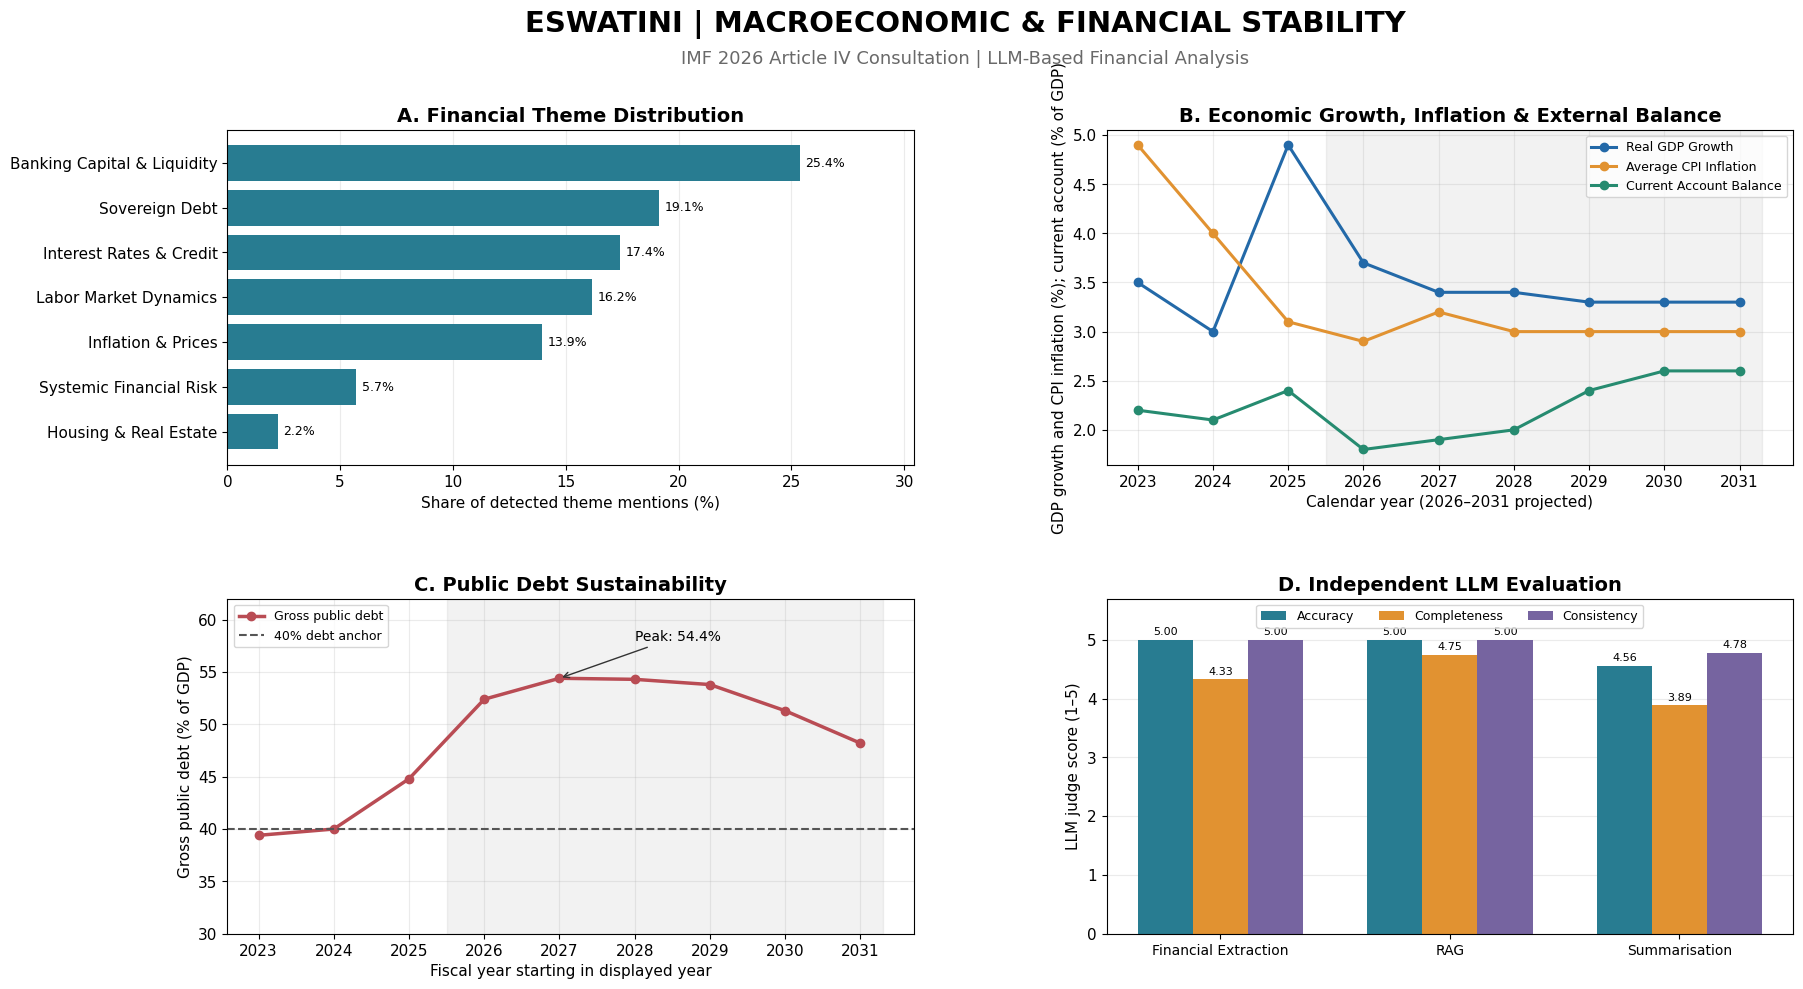

In [38]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np

# Prepare long-format data for plotting
trend_long = pd.melt(
    trend_df,
    id_vars=["Year", "Period"],
    value_vars=[
        "Real GDP Growth",
        "Average CPI Inflation",
        "Current Account Balance",
        "Public Debt"
    ],
    var_name="Indicator",
    value_name="Value"
)

score_df = evaluation_df.groupby("task")[
    ["accuracy", "completeness", "consistency"]
].mean().reset_index()

score_long = pd.melt(
    score_df,
    id_vars="task",
    var_name="Metric",
    value_name="Score"
)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.facecolor": "white"
})

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.subplots_adjust(
    left=0.09, right=0.96,
    top=0.87, bottom=0.20,
    hspace=0.40, wspace=0.28
)

fig.suptitle(
    "ESWATINI | MACROECONOMIC & FINANCIAL STABILITY",
    fontsize=21, fontweight="bold", y=0.97
)
fig.text(
    0.5, 0.925,
    "IMF 2026 Article IV Consultation | LLM-Based Financial Analysis",
    ha="center", fontsize=13, color="dimgray"
)

# Financial themes
ax = axes[0, 0]
theme_plot = theme_df.sort_values("percentage")

bars = ax.barh(
    theme_plot["theme"],
    theme_plot["percentage"],
    color="#287C91"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlim(0, max(theme_plot["percentage"]) * 1.20)
ax.set_xlabel("Share of detected theme mentions (%)")
ax.set_title("A. Financial Theme Distribution", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

# Economic trends
ax = axes[0, 1]

trend_colors = {
    "Real GDP Growth": "#2369A8",
    "Average CPI Inflation": "#E19231",
    "Current Account Balance": "#268B70"
}

for indicator, color in trend_colors.items():
    data = trend_long[trend_long["Indicator"] == indicator]
    ax.plot(
        data["Year"], data["Value"],
        marker="o", linewidth=2.2,
        label=indicator, color=color
    )

ax.axvspan(2025.5, 2031.3, color="gray", alpha=0.10)
ax.set_title("B. Economic Growth, Inflation & External Balance",
             fontweight="bold")
ax.set_xlabel("Calendar year (2026–2031 projected)")
ax.set_ylabel("GDP growth and CPI inflation (%); current account (% of GDP)")
ax.set_xticks(trend_df["Year"])
ax.legend(fontsize=9, loc="upper right")
ax.grid(alpha=0.25)

#Public debt
ax = axes[1, 0]

debt = trend_long[trend_long["Indicator"] == "Public Debt"]

ax.plot(
    debt["Year"], debt["Value"],
    color="#B94C54", marker="o",
    linewidth=2.5, label="Gross public debt"
)

ax.axhline(
    40, color="#555555", linestyle="--",
    linewidth=1.5, label="40% debt anchor"
)
ax.axvspan(2025.5, 2031.3, color="gray", alpha=0.10)

ax.annotate(
    "Peak: 54.4%",
    xy=(2027, 54.4),
    xytext=(2028, 58),
    arrowprops={"arrowstyle": "->", "color": "#333333"},
    fontsize=10
)

ax.set_title("C. Public Debt Sustainability", fontweight="bold")
ax.set_xlabel("Fiscal year starting in displayed year")
ax.set_ylabel("Gross public debt (% of GDP)")
ax.set_xticks(debt["Year"])
ax.set_ylim(30, 62)
ax.legend(fontsize=9)
ax.grid(alpha=0.25)

# Independent LLM evaluation
ax = axes[1, 1]

tasks = ["Financial Extraction", "RAG", "Summarisation"]
metrics = ["accuracy", "completeness", "consistency"]
colors = ["#287C91", "#E19231", "#7664A0"]

x = np.arange(len(tasks))
width = 0.24

for i, metric in enumerate(metrics):
    values = [
        score_df.loc[
            score_df["task"] == task, metric
        ].iloc[0]
        for task in tasks
    ]

    bars = ax.bar(
        x + (i - 1) * width,
        values, width,
        label=metric.capitalize(),
        color=colors[i]
    )

    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(tasks, fontsize=10)
ax.set_ylim(0, 5.7)
ax.set_ylabel("LLM judge score (1–5)")
ax.set_title("D. Independent LLM Evaluation", fontweight="bold")
ax.legend(ncol=3, fontsize=9, loc="upper center")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

dashboard_file = output_dir / "eswatini_imf_dashboard.png"

fig.savefig(
    dashboard_file,
    dpi=320,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)